<a href="https://colab.research.google.com/github/JaylinQuinn/bafad-research-track/blob/main/week03/BAFAD_Week03_Exercise1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAFAD Week 3 — Exercise 1: Multi-Mode Noise Injection Pipeline

**Week:** 3 · Oct 12–18, 2026  
**Your name:** *(fill in)*  
**Commit when done:** `feat: implement multi-mode noise injection pipeline`

---

## Overview

This exercise extends the Week 2 injection function in two directions: a new injection mode
(sensor blackout) and label-driven window extraction. Instead of hardcoding window boundaries,
you derive them from a binary anomaly label array — the same format used by the real SKAB dataset.

Both extensions are small code changes. The goal is to understand *why* each design decision
matters before you apply these functions to real data in Week 4.

## Section 1: Setup & Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f'NumPy version: {np.__version__}')
print('Imports successful.')

NumPy version: 2.1.3
Imports successful.


## Section 2: Baseline Sensor Stream

Run this cell as-is. It re-uses the same generator from Week 2.

In [2]:
def generate_sensor_stream(samples=1000, features=3, seed=42):
    """Generates synthetic multivariate time-series baseline sensor data."""
    np.random.seed(seed)
    t = np.linspace(0, 50, samples)
    stream = np.zeros((samples, features))
    for f in range(features):
        stream[:, f] = np.sin(t * (f + 1)) + np.random.normal(0, 0.05, samples)
    return stream

clean_stream = generate_sensor_stream(samples=1000, features=3)
print(f'Clean stream shape: {clean_stream.shape}')   # Expected: (1000, 3)
print(f'Value range: [{clean_stream.min():.3f}, {clean_stream.max():.3f}]')
assert clean_stream.shape == (1000, 3)
print('Shape assertion passed.')

Clean stream shape: (1000, 3)
Value range: [-1.126, 1.157]
Shape assertion passed.


## Section 3: Simulate SKAB-Format Anomaly Labels

Run this cell as-is. It creates a binary label array with two anomaly windows of different lengths —
the same structure you will find in the real SKAB `alldata/` CSV files.

In [3]:
# Simulate SKAB-style anomaly labels: two windows of different lengths
labels = np.zeros(1000, dtype=int)
labels[200:280] = 1    # Window A: 80 timesteps
labels[600:750] = 1    # Window B: 150 timesteps

print(f'Total anomaly rows: {labels.sum()}')
print(f'Anomaly fraction:   {labels.mean():.3f}')
assert labels.sum() == 230
print('Label assertion passed.')

Total anomaly rows: 230
Anomaly fraction:   0.230
Label assertion passed.


## Section 4: Implement `extract_anomaly_windows()`

**Your task:** Complete the function below.

The function must:
1. Walk through `anomaly_labels` one element at a time
2. Record the start index whenever it sees the first `1` in a run
3. Record the end index (exclusive) whenever it sees the first `0` after a run
4. Handle the edge case where a run of `1`s reaches the end of the array
5. Return a list of `(start_idx, end_idx)` tuples

**Hint:** Use a boolean flag (`in_window`) to track whether you are currently inside a window.

In [12]:

def extract_anomaly_windows(anomaly_labels):
    """
    Converts a binary anomaly label array into a list of (start, end) tuples.
    Each contiguous run of 1s becomes one window. End index is exclusive.

    Parameters
    ----------
    anomaly_labels : array-like of 0/1 integers, length T

    Returns
    -------
    windows : list of (start_idx, end_idx) tuples
    """
    windows = []
    in_window = False
    start     = 0

    # TODO: Walk through anomaly_labels with enumerate()
    # - When you see label==1 and in_window is False: record start, set in_window=True
    # - When you see label==0 and in_window is True: append (start, i) to windows, set in_window=False
    for i, label in enumerate(anomaly_labels):
        if label == 1 and not in_window:
            start = i
            in_window = True
        elif label == 0 and in_window:
            windows.append((start, i))
            in_window = False

    # TODO: Handle the edge case - if in_window is still True at the end of the loop,
    # append (start, len(anomaly_labels)) to windows
    if in_window:
        windows.append((start, len(anomaly_labels)))

    return windows


windows = extract_anomaly_windows(labels)
print(f'Extracted windows: {windows}')

assert len(windows) == 2, f'Expected 2 windows, got {len(windows)}'
assert windows[0] == (200, 280), f'Window A: expected (200, 280), got {windows[0]}'
assert windows[1] == (600, 750), f'Window B: expected (600, 750), got {windows[1]}'
print('Window extraction assertions passed.')


Extracted windows: [(200, 280), (600, 750)]
Window extraction assertions passed.


## Section 5: Implement `inject_noise_profile()`

**Your task:** Complete the two TODO branches below.

The function must:
1. Create a copy of `raw_data`
2. Compute `window_rows = end_idx - start_idx` and `n_features = poisoned_data.shape[1]`
3. For `mode='noise'`: generate Gaussian noise of shape `(window_rows, n_features)` and **add** it to the window
4. For `mode='blackout'`: set the window to exactly `0.0`
5. For any other mode: raise `ValueError`
6. Return the modified copy

In [13]:
def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """
    Injects a synthetic noise profile into a localized index window.

    Parameters
    ----------
    raw_data   : np.ndarray, shape (T, F)
    start_idx  : int — first row of the injection window (inclusive)
    end_idx    : int — last row of the injection window (exclusive)
    variance   : float — std dev for mode='noise' (ignored for 'blackout')
    mode       : str — 'noise' or 'blackout'

    Returns
    -------
    poisoned_data : np.ndarray, shape (T, F)
    """
    poisoned_data = raw_data.copy()
    window_rows   = end_idx - start_idx
    n_features    = poisoned_data.shape[1]

    if mode == 'noise':
        # TODO: Generate Gaussian noise of shape (window_rows, n_features)
        # and add it to poisoned_data[start_idx:end_idx, :]
        noise = np.random.normal(0, variance, (window_rows, n_features))
        poisoned_data[start_idx:end_idx, :] += noise
        pass

    elif mode == 'blackout':
        # TODO: Set poisoned_data[start_idx:end_idx, :] to exactly 0.0
        poisoned_data[start_idx:end_idx, :] = 0.0
        pass

    else:
        raise ValueError(f"Unknown mode: '{mode}'. Choose 'noise' or 'blackout'.")

    return poisoned_data


# Apply to both windows, both modes
np.random.seed(42)
noisy_stream    = clean_stream.copy()
blackout_stream = clean_stream.copy()

for start, end in windows:
    noisy_stream    = inject_noise_profile(noisy_stream,    start, end, variance=2.5, mode='noise')
    blackout_stream = inject_noise_profile(blackout_stream, start, end, mode='blackout')

# Shape checks
assert noisy_stream.shape    == clean_stream.shape
assert blackout_stream.shape == clean_stream.shape

# Outside-window rows must be unchanged
assert np.array_equal(noisy_stream[:200],    clean_stream[:200])
assert np.array_equal(noisy_stream[280:600], clean_stream[280:600])
assert np.array_equal(noisy_stream[750:],    clean_stream[750:])

# Blackout windows must be exactly zero
assert np.all(blackout_stream[200:280, :] == 0.0), 'Window A should be zero'
assert np.all(blackout_stream[600:750, :] == 0.0), 'Window B should be zero'

# Outside-window rows unchanged in blackout stream
assert np.array_equal(blackout_stream[:200],    clean_stream[:200])
assert np.array_equal(blackout_stream[280:600], clean_stream[280:600])
assert np.array_equal(blackout_stream[750:],    clean_stream[750:])

# Noise injection must raise signal magnitude
for start, end in windows:
    clean_mag = np.abs(clean_stream[start:end]).mean()
    noisy_mag = np.abs(noisy_stream[start:end]).mean()
    assert noisy_mag > clean_mag
    print(f'Window {start}–{end}: clean={clean_mag:.4f}, noisy={noisy_mag:.4f}')

print('All assertions passed.')

Window 200–280: clean=0.6539, noisy=2.0498
Window 600–750: clean=0.6436, noisy=2.0865
All assertions passed.


## Section 6: Three-Panel Visualization

**Your task:** Complete the plot scaffold below.

Requirements:
- Three vertically stacked subplots sharing the x-axis
- Top panel: Sensor 1 from `clean_stream` (blue, `#0EA5E9`)
- Middle panel: Sensor 1 from `noisy_stream` (red, `#EF4444`)
- Bottom panel: Sensor 1 from `blackout_stream` (purple, `#8B5CF6`)
- All panels: shaded `axvspan` for each window in `windows`
- All panels: legend and y-label
- Overall figure title
- Save as `week03_exercise1_plot.png`

Refer to the three-panel scaffold in the Week 3 Resource Guide.

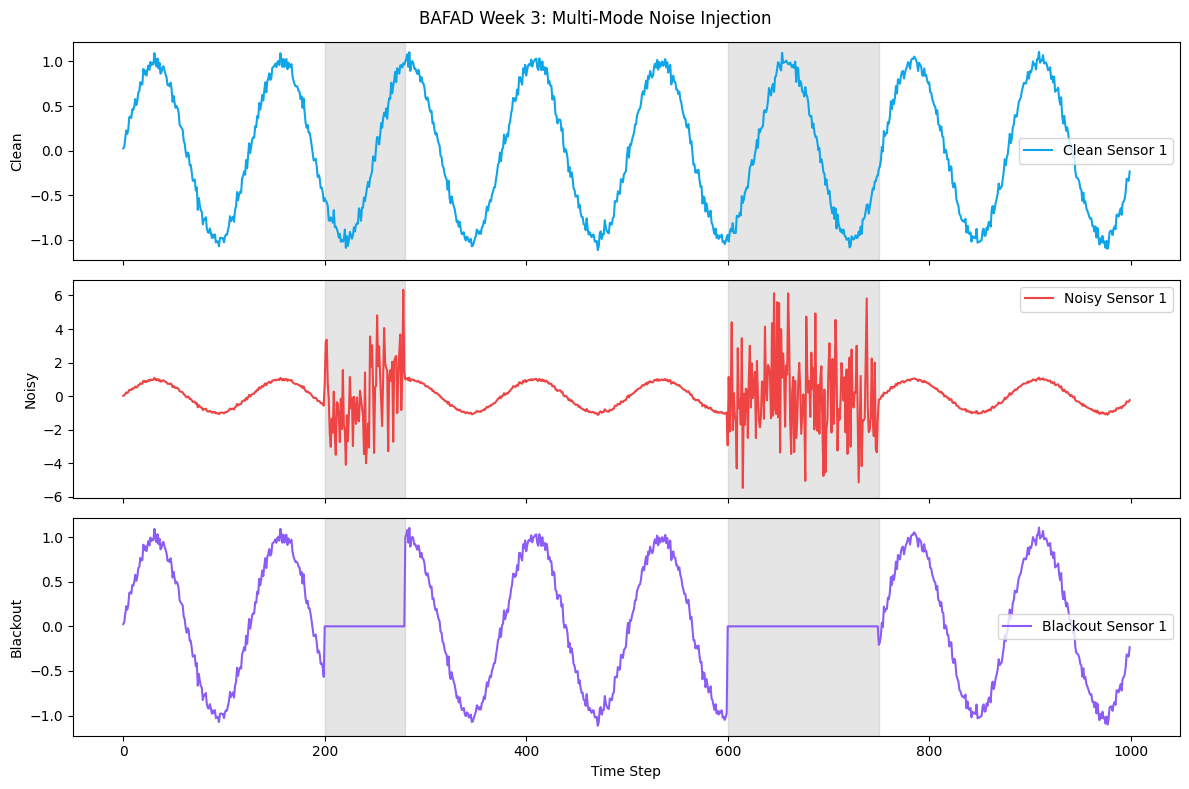

Plot saved.


In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
t = np.arange(1000)

# TODO: Plot clean stream on axes[0]
axes[0].plot(t, clean_stream[:, 0], color='#0EA5E9', label='Clean Sensor 1')
axes[0].set_ylabel('Clean')
axes[0].legend()
for start, end in windows:
    axes[0].axvspan(start, end, color='gray', alpha=0.2)

# TODO: Plot noisy stream on axes[1]
axes[1].plot(t, noisy_stream[:, 0], color='#EF4444', label='Noisy Sensor 1')
axes[1].set_ylabel('Noisy')
axes[1].legend()
for start, end in windows:
    axes[1].axvspan(start, end, color='gray', alpha=0.2)

# TODO: Plot blackout stream on axes[2]
axes[2].plot(t, blackout_stream[:, 0], color='#8B5CF6', label='Blackout Sensor 1')
axes[2].set_ylabel('Blackout')
axes[2].set_xlabel('Time Step')
axes[2].legend()
for start, end in windows:
    axes[2].axvspan(start, end, color='gray', alpha=0.2)

# TODO: Add overall figure title and save
fig.suptitle('BAFAD Week 3: Multi-Mode Noise Injection')

plt.tight_layout()
plt.savefig('week03_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved.')

## Section 7: Interpretation Questions

Answer each question in 2–4 sentences.

**Q1.** Compare the two injection modes visually. What does each mode look like inside the anomaly
windows, and how would an autoencoder's reconstruction error differ between them?

> *[The noise mode makes the data look all over the place with a bunch of random spikes while the blackout mode makes the signal completely flat at zero. I think the autoencoder would have a harder time recreating the noisy data because it is so unpredictable. The blackout would also cause errors because the normal sensor data is missing.]*

**Q2.** The two anomaly windows have different lengths (80 and 150 timesteps). Does
`inject_noise_profile()` require any modification to handle variable-length windows? Explain why
or why not.

> *[No, I wouldn't need to change the function because it already figures out the window size using the starting and ending indexes. This means it can handle different window lengths on its own without me having to change anything.]*

**Q3.** Suppose the SKAB file you load has no anomaly windows (all `anomaly` labels are 0).
What does `extract_anomaly_windows()` return, and what happens when you iterate over that
return value in the injection loop?

> *[If there are no anomalies, the function would just return an empty list because there is nothing to detect. When the injection loop runs, it would basically skip everything since there are no windows to go through. The original data would stay the same because nothing was changed.]*

## Section 8: Git Commit

When all assertions pass and the plot renders, run the following in a Colab terminal cell:

```bash
git add week03/BAFAD_Week03_Exercise1.ipynb
git commit -m "feat: implement multi-mode noise injection pipeline"
git push origin main
```

Bring your GitHub commit link and the saved plot to the Week 3 check-in.